# 01 — Mean image and autocorrelation

**Goal:** check whether Firefly images share a common signal by averaging images of the
same size with a growing sample size N (10, 100, all).

Image content varies from image to image and averages out as N grows. A signal shared
by every image (e.g. a periodic upsampling pattern) does not, so it should emerge in the
mean. The autocorrelation of the mean then reveals periodicity as a lattice of peaks
whose spacing is the period.

Images are grouped by size because the pattern position may depend on the image grid
(and portrait vs landscape may differ, as for the Adobe pattern).

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter, maximum_filter

from firefly_detection.config import RESULTS_DIR
from firefly_detection.data import group_by_size, list_images, load_image

OUT = RESULTS_DIR / "01_mean_autocorr"
OUT.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(0)

## 1. Images grouped by size

In [2]:
groups = group_by_size(list_images("firefly"))
# Random, seeded order so that "the first N images" is a random sample;
# samples are nested: the first 10 are part of the first 100.
groups = {size: [paths[i] for i in rng.permutation(len(paths))] for size, paths in groups.items()}
pd.DataFrame([(f"{w}x{h}", len(p)) for (w, h), p in groups.items()], columns=["size (WxH)", "n images"])

,size (WxH),n images
0,2304x1792,271
1,1792x2304,252
2,2048x2048,243
3,2688x1536,234


## 2. Running mean for N = 10, 100, all

Images are converted to float luminance and read once per size; the running sum is
snapshotted at each N. Means are cached in `results/01_mean_autocorr/` so re-running the
notebook is fast (delete the folder to recompute).

In [3]:
def running_means(paths, checkpoints, gray=True):
    """Mean over the first n paths for each n in checkpoints, in a single pass."""
    checkpoints = sorted(set(checkpoints))
    means, acc = {}, None
    for k, path in enumerate(paths[: checkpoints[-1]], 1):
        img = load_image(path, gray=gray, dtype=np.float64)
        acc = img if acc is None else acc + img
        if k in checkpoints:
            means[k] = acc / k
    return means


def cached_means(size, paths, ns):
    files = {n: OUT / f"mean_{size[0]}x{size[1]}_n{n}.npy" for n in ns}
    if all(f.exists() for f in files.values()):
        return {n: np.load(f) for n, f in files.items()}
    means = running_means(paths, ns)
    for n, m in means.items():
        np.save(files[n], m)
    return means


means = {}  # (size, N) -> mean luminance image
for size, paths in groups.items():
    ns = [10, 100, len(paths)]
    for n, m in cached_means(size, paths, ns).items():
        means[size, n] = m
    print(f"{size[0]}x{size[1]}: N = {ns}")

2304x1792: N = [10, 100, 271]


1792x2304: N = [10, 100, 252]


2048x2048: N = [10, 100, 243]


2688x1536: N = [10, 100, 234]


## 3. The mean images

As N grows, scene content should blur into a smooth average, leaving any shared
fine-scale structure behind.

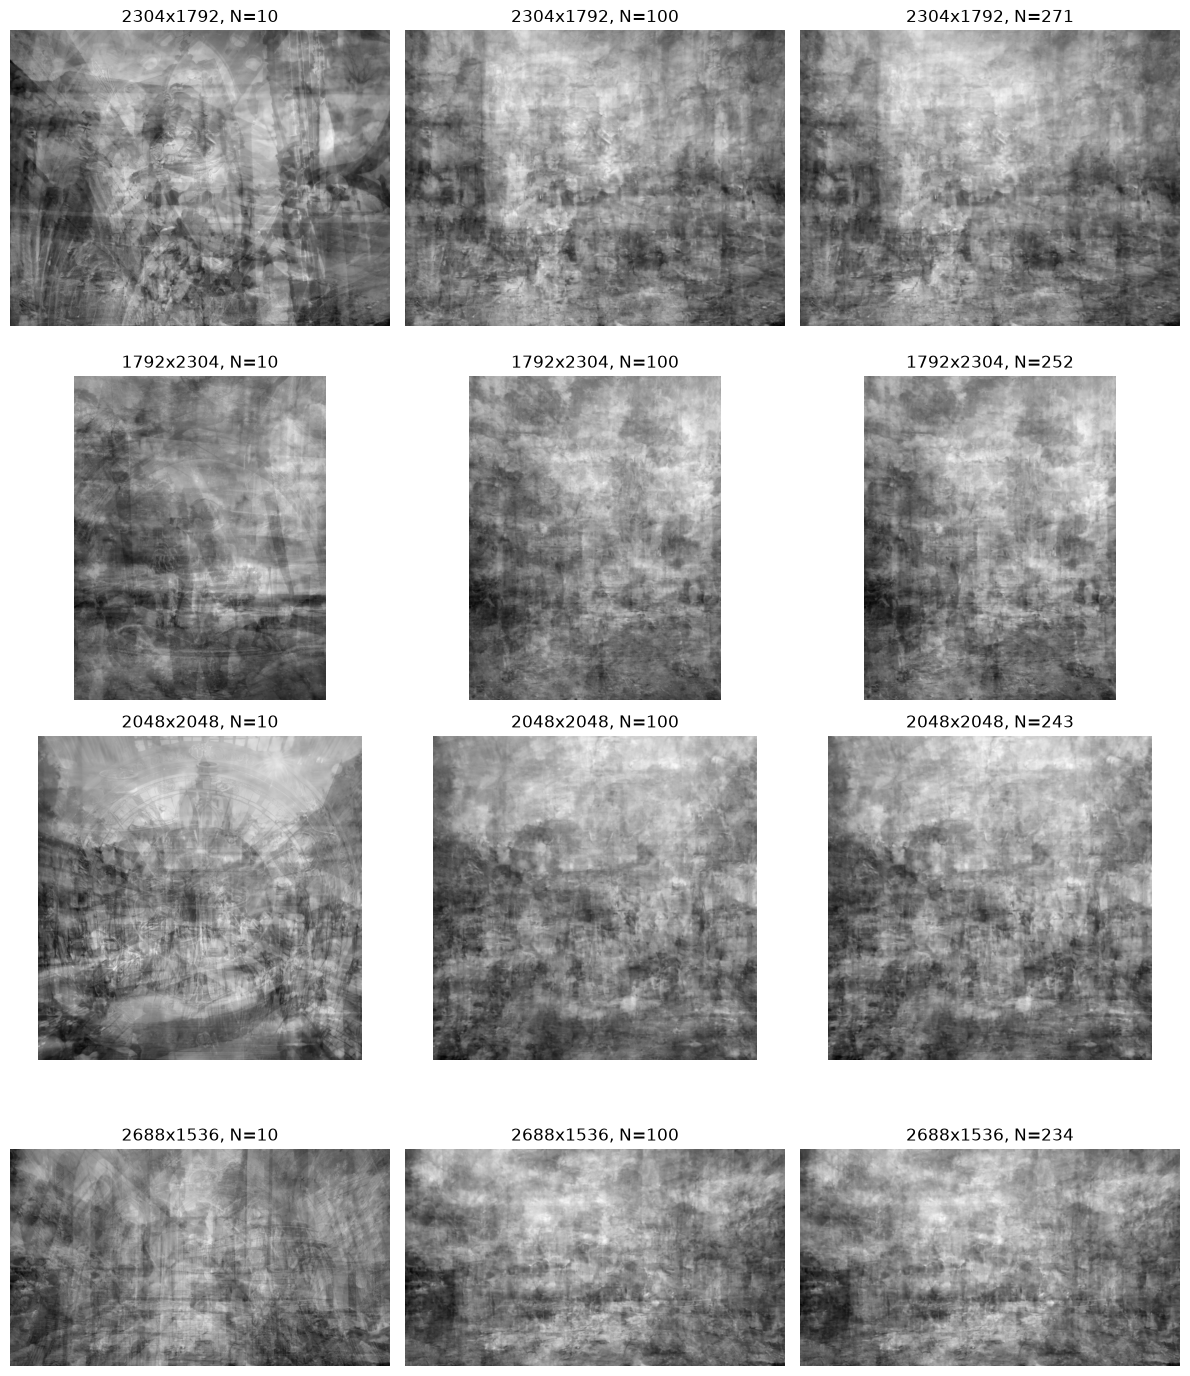

In [4]:
sizes = list(groups)
fig, axes = plt.subplots(len(sizes), 3, figsize=(12, 3.6 * len(sizes)))
for row, size in zip(axes, sizes):
    ns = sorted(n for s, n in means if s == size)
    for ax, n in zip(row, ns):
        ax.imshow(means[size, n], cmap="gray")
        ax.set_title(f"{size[0]}x{size[1]}, N={n}")
        ax.axis("off")
fig.tight_layout()

## 4. High-pass filtering

The mean still contains low-frequency content (average brightness layout, leftover
scene structure). We remove it with `x - gaussian_blur(x, sigma)` to focus on
fine-scale structure. This filter is linear, so the high-pass of the mean equals the
mean of the high-passed images.

Zoom on a central 128x128 crop to see any pattern directly.

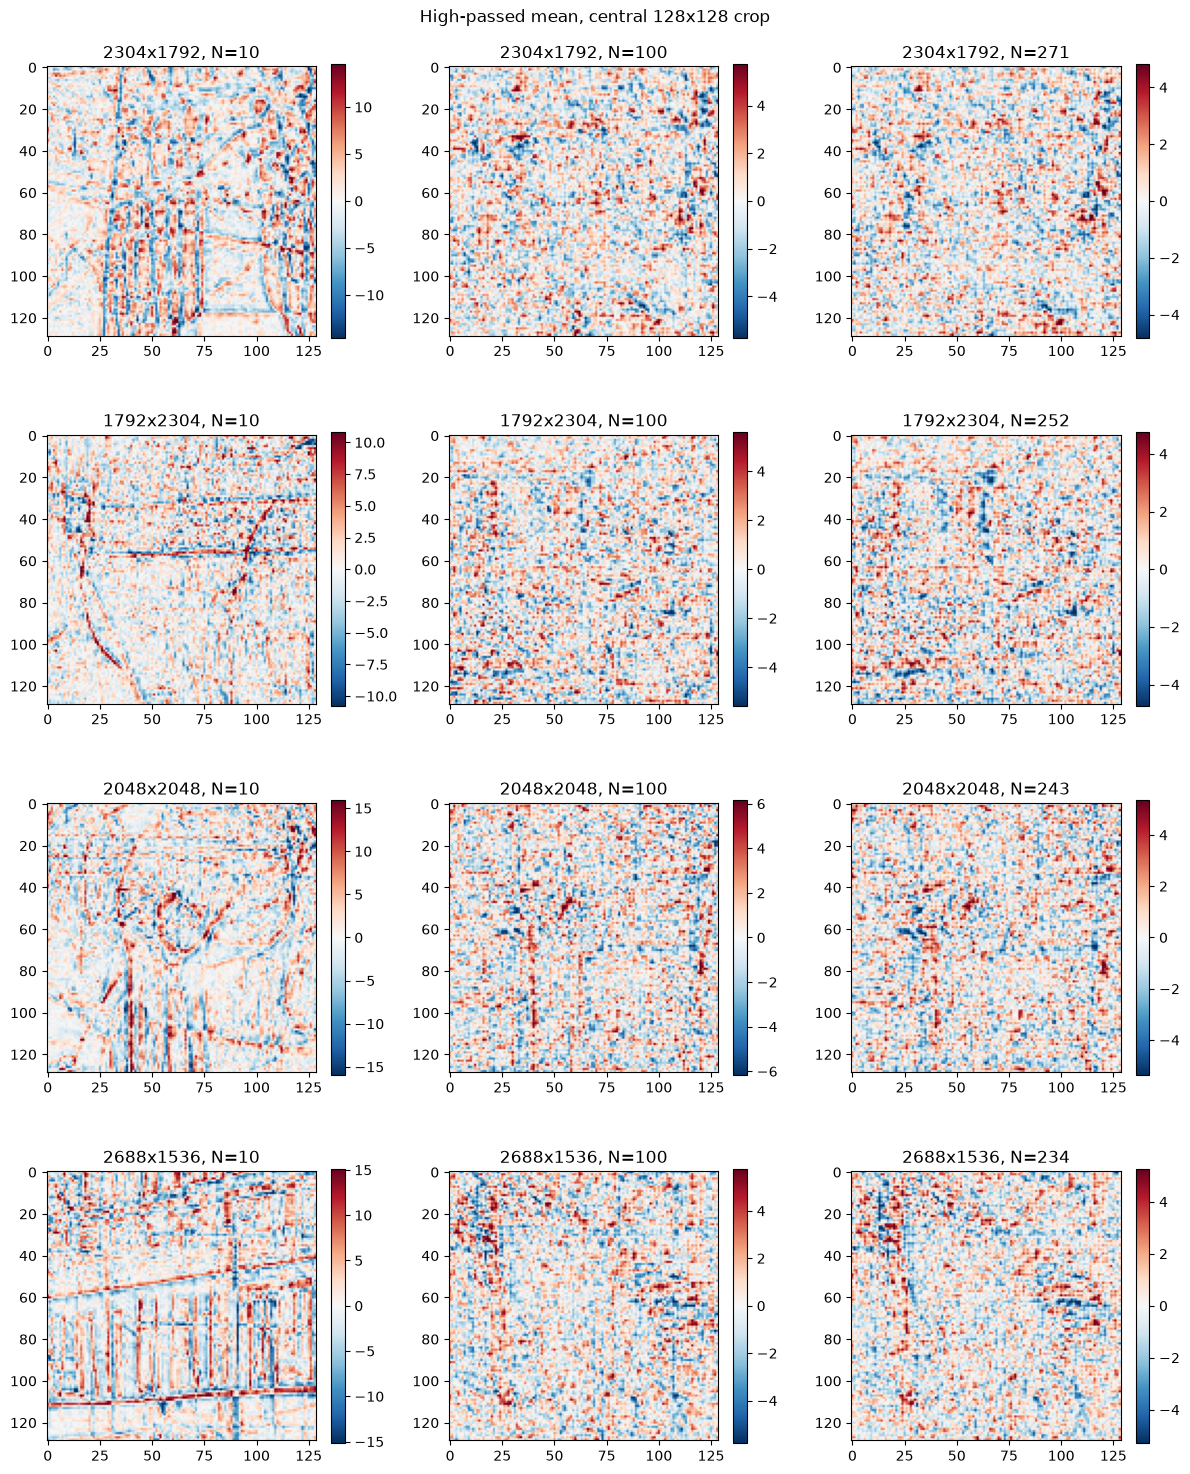

In [5]:
SIGMA = 2.0


def highpass(x, sigma=SIGMA):
    return x - gaussian_filter(x, sigma, mode="wrap")


def crop_center(x, half):
    cy, cx = x.shape[0] // 2, x.shape[1] // 2
    return x[cy - half : cy + half + 1, cx - half : cx + half + 1]


hp = {key: highpass(m) for key, m in means.items()}

fig, axes = plt.subplots(len(sizes), 3, figsize=(12, 3.8 * len(sizes)))
for row, size in zip(axes, sizes):
    ns = sorted(n for s, n in means if s == size)
    for ax, n in zip(row, ns):
        c = crop_center(hp[size, n], 64)
        v = np.percentile(np.abs(c), 99.5)
        im = ax.imshow(c, cmap="RdBu_r", vmin=-v, vmax=v)
        ax.set_title(f"{size[0]}x{size[1]}, N={n}")
        fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("High-passed mean, central 128x128 crop")
fig.tight_layout()

## 5. Autocorrelation

Normalized circular autocorrelation via the Wiener–Khinchin theorem:
$R = \mathcal{F}^{-1}\{|\mathcal{F}(x - \bar x)|^2\}$, scaled so that $R(0,0) = 1$.
A periodic signal with period $p$ produces peaks at lags that are multiples of $p$.
The zero-lag peak is excluded from the color scale.

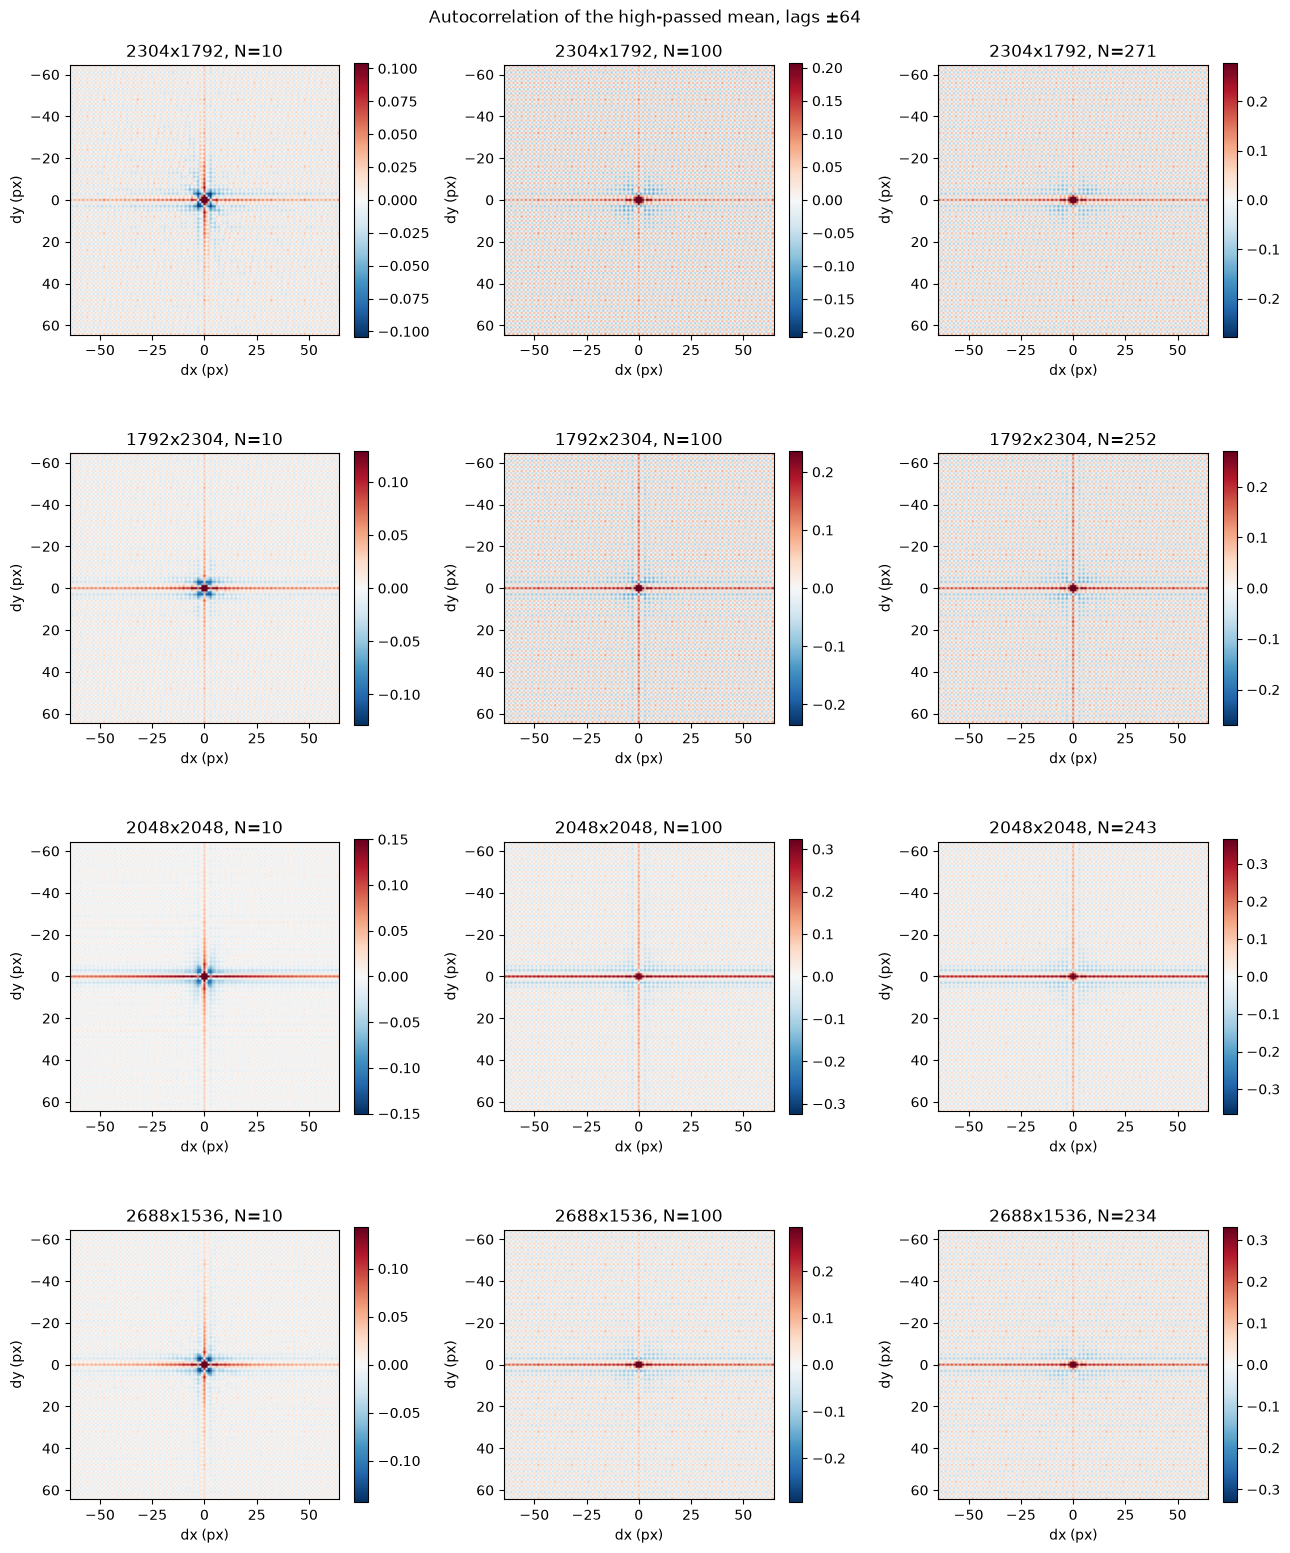

In [6]:
LAG = 64


def autocorrelation(x):
    x = x - x.mean()
    r = np.fft.ifft2(np.abs(np.fft.fft2(x)) ** 2).real
    return np.fft.fftshift(r / r.flat[0])


acf = {key: crop_center(autocorrelation(h), LAG) for key, h in hp.items()}

fig, axes = plt.subplots(len(sizes), 3, figsize=(13, 4 * len(sizes)))
ext = (-LAG - 0.5, LAG + 0.5, LAG + 0.5, -LAG - 0.5)
for row, size in zip(axes, sizes):
    ns = sorted(n for s, n in means if s == size)
    for ax, n in zip(row, ns):
        r = acf[size, n].copy()
        r[LAG - 2 : LAG + 3, LAG - 2 : LAG + 3] = 0  # hide the zero-lag peak
        v = np.abs(r).max()
        im = ax.imshow(acf[size, n], cmap="RdBu_r", vmin=-v, vmax=v, extent=ext)
        ax.set_title(f"{size[0]}x{size[1]}, N={n}")
        ax.set_xlabel("dx (px)")
        ax.set_ylabel("dy (px)")
        fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle(f"Autocorrelation of the high-passed mean, lags ±{LAG}")
fig.tight_layout()

### Profiles along the axes

Rows and columns through the origin make the period easier to read than the 2D map.

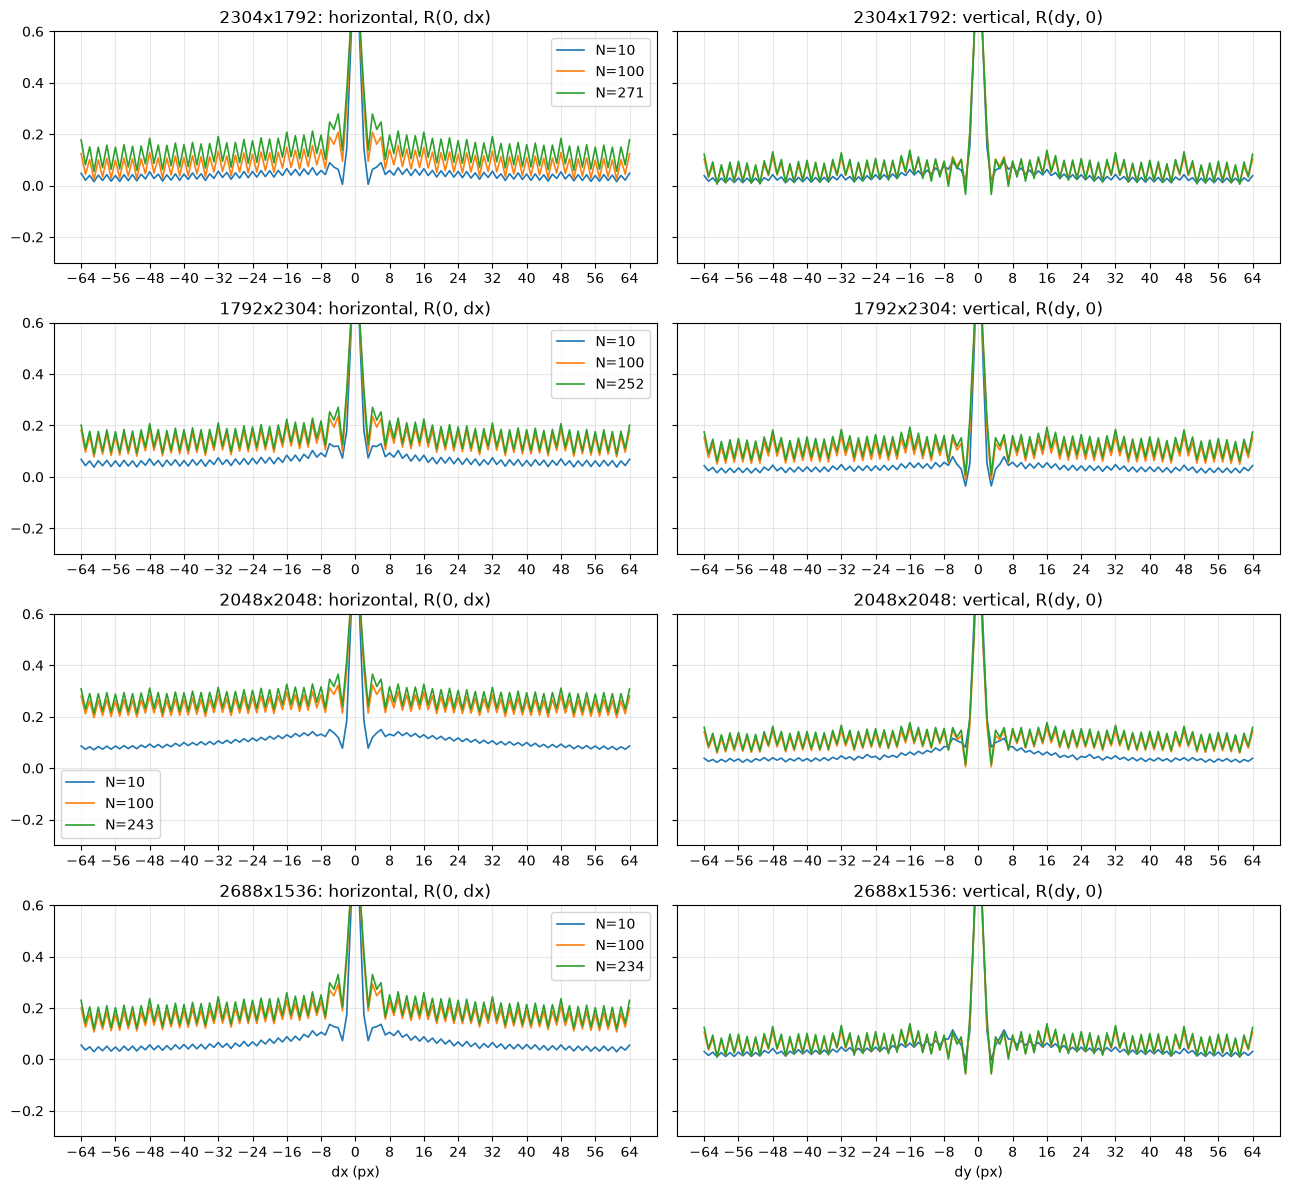

In [7]:
lags = np.arange(-LAG, LAG + 1)
fig, axes = plt.subplots(len(sizes), 2, figsize=(13, 3 * len(sizes)), sharey=True)
for row, size in zip(axes, sizes):
    ns = sorted(n for s, n in means if s == size)
    for n in ns:
        r = acf[size, n]
        row[0].plot(lags, r[LAG, :], lw=1.2, label=f"N={n}")
        row[1].plot(lags, r[:, LAG], lw=1.2, label=f"N={n}")
    row[0].set_title(f"{size[0]}x{size[1]}: horizontal, R(0, dx)")
    row[1].set_title(f"{size[0]}x{size[1]}: vertical, R(dy, 0)")
    for ax in row:
        ax.set_ylim(-0.3, 0.6)
        ax.set_xticks(np.arange(-LAG, LAG + 1, 8))
        ax.grid(alpha=0.3)
    row[0].legend()
axes[-1, 0].set_xlabel("dx (px)")
axes[-1, 1].set_xlabel("dy (px)")
fig.tight_layout()

## 6. Strongest peaks and how they grow with N

In [8]:
def peaks(r, k=8, exclude=2):
    """k largest positive local maxima, excluding lags near the origin; one per ± pair."""
    c = r.shape[0] // 2
    ys, xs = np.nonzero((r == maximum_filter(r, size=3, mode="wrap")) & (r > 0))
    out = [
        (y - c, x - c, r[y, x])
        for y, x in zip(ys, xs)
        if max(abs(y - c), abs(x - c)) > exclude and (y - c, x - c) > (0, 0)
    ]
    return sorted(out, key=lambda p: -p[2])[:k]


rows = []
for (size, n), r in acf.items():
    for rank, (dy, dx, v) in enumerate(peaks(r), 1):
        rows.append((f"{size[0]}x{size[1]}", n, rank, dy, dx, round(v, 3)))
df_peaks = pd.DataFrame(rows, columns=["size", "N", "rank", "dy", "dx", "R"])
df_peaks.pivot_table(index=["size", "N"], columns="rank", values="R")

rank               1      2      3      4      5      6      7      8
size      N                                                          
1792x2304 10   0.129  0.120  0.102  0.093  0.088  0.084  0.084  0.078
          100  0.236  0.226  0.207  0.203  0.192  0.191  0.190  0.189
          252  0.271  0.253  0.229  0.224  0.217  0.213  0.211  0.210
2048x2048 10   0.150  0.142  0.137  0.134  0.132  0.130  0.126  0.124
          100  0.323  0.313  0.297  0.296  0.287  0.285  0.285  0.285
          243  0.365  0.346  0.327  0.326  0.316  0.315  0.314  0.314
2304x1792 10   0.094  0.089  0.076  0.070  0.068  0.066  0.065  0.063
          100  0.208  0.189  0.156  0.149  0.143  0.140  0.138  0.135
          271  0.278  0.247  0.212  0.208  0.196  0.196  0.194  0.191
2688x1536 10   0.136  0.115  0.112  0.105  0.097  0.090  0.088  0.083
          100  0.293  0.269  0.237  0.229  0.226  0.222  0.219  0.214
          234  0.330  0.298  0.263  0.259  0.251  0.248  0.246  0.244

In [9]:
# Lags of the top peaks with all images
df_peaks[df_peaks.N == df_peaks.groupby("size").N.transform("max")].pivot_table(
    index="size", columns="rank", values=["dy", "dx"], aggfunc="first"
)

dx                            dy                     
rank       1  2   3   4   5   6   7   8  1  2  3  4  5  6  7  8
size                                                           
1792x2304  4  6  10  16   8  14  12  32  0  0  0  0  0  0  0  0
2048x2048  4  6  10  16   8  14  32  12  0  0  0  0  0  0  0  0
2304x1792  4  6  10  16  12   8  14  32  0  0  0  0  0  0  0  0
2688x1536  4  6  10  16   8  12  14  32  0  0  0  0  0  0  0  0

## Observations

_To fill in after looking at the figures._